# Data Preprocessing for Image Classification Project


This notebook contains all preprocessing steps used in the project:

- loading the dataset
- splitting into train/validation/test
- visualizing example images
- checking class distribution
- applying data augmentation
- building a clean input pipeline (cache + shuffle)
- preparing normalization layer for Model 1 (CNN)

These preprocessed datasets will be reused in all three models.


In [1]:
# Core
import numpy as np
import os
import pathlib

# TensorFlow / Keras
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, RandomFlip, RandomRotation, RandomZoom

# Pretrained models
from tensorflow.keras.applications import VGG16, ResNet50, MobileNetV2
from tensorflow.keras.applications.vgg16 import preprocess_input as vgg_preprocess
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_preprocess
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input as mobilenet_preprocess

# Image loading and preprocessing
from tensorflow.keras.preprocessing import image
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Evaluation
from sklearn.metrics import confusion_matrix, classification_report

# Utilities
import pandas as pd
from collections import Counter

C:\Users\ronis\anaconda3\envs\keras\Lib\site-packages\h5py\__init__.py:36: UserWarning: h5py is running against HDF5 1.14.6 when it was built against 1.14.5, this may cause problems
  _warn(("h5py is running against HDF5 {0} when it was built against {1}, "


###  Loading the dataset

- Images are loaded from `data/train` and `data/test`
- We use validation_split = 0.15 to create a validation set
- All images are resized to 224×224 to match CNN and pre-trained model requirements
- Class names are automatically detected from folder names


In [2]:
img_size = (224, 224)

train_ds = tf.keras.utils.image_dataset_from_directory(
    "data/train",
    validation_split=0.15,
    subset="training",
    seed=42,
    image_size=(224, 224),
    batch_size=32
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    "data/train",
    validation_split=0.15,
    subset="validation",
    seed=42,
    image_size=(224, 224),
    batch_size=32
)

test_ds = tf.keras.preprocessing.image_dataset_from_directory(
    "data/test",
    image_size=img_size,
    batch_size=32
)

Found 260 files belonging to 5 classes.
Using 221 files for training.
Found 260 files belonging to 5 classes.
Using 39 files for validation.
Found 51 files belonging to 5 classes.


In [3]:
class_names = train_ds.class_names

def get_class_distribution(ds):
    counter = Counter()
    for _, labels in ds:
        for label in labels.numpy():
            counter[int(label)] += 1
    return counter

def print_distribution(name, ds, class_names):
    dist = get_class_distribution(ds)
    print(f"{name}:")
    for idx, cname in enumerate(class_names):
        print(f"  {cname}: {dist.get(idx, 0)}")
    print()

print_distribution("Train", train_ds, class_names)
print_distribution("Validation", val_ds, class_names)
print_distribution("Test", test_ds, class_names)



Train:
  book: 45
  cat: 44
  dog: 36
  mug: 42
  rabbit: 54

Validation:
  book: 5
  cat: 9
  dog: 6
  mug: 8
  rabbit: 11

Test:
  book: 10
  cat: 10
  dog: 11
  mug: 10
  rabbit: 10



#### Class distributions

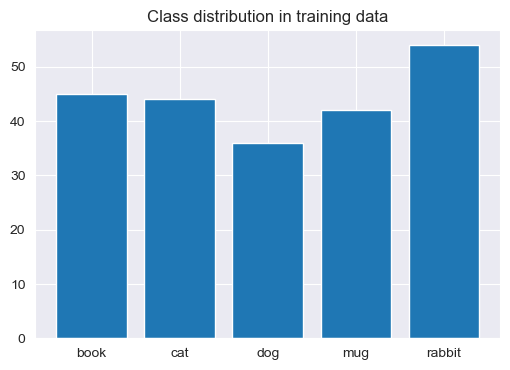

In [4]:
dist = get_class_distribution(train_ds)

plt.figure(figsize=(6,4))
plt.bar(class_names, [dist[i] for i in range(len(class_names))])
plt.title("Class distribution in training data")
plt.show()


#### Sample images

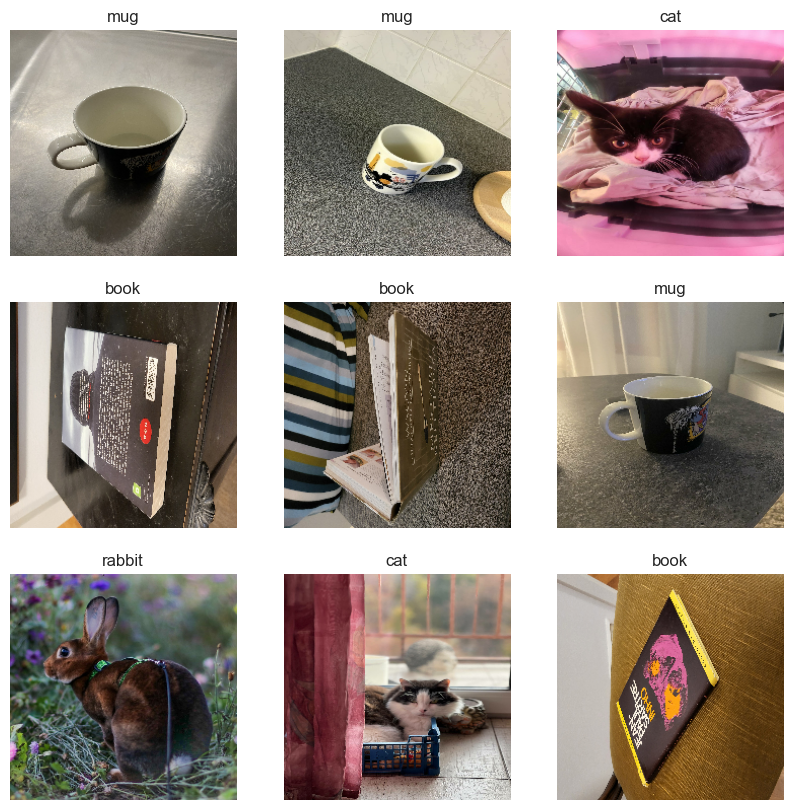

In [5]:
plt.figure(figsize=(10,10))

for images, labels in train_ds.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i+1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[int(labels[i].numpy())])
        plt.axis("off")


### Data augmentation

We apply light augmentation only to the **training dataset**:

- horizontal flip  
- small rotation  
- zoom  

This improves generalization and helps with small datasets.


In [6]:
data_augmentation = Sequential([
    RandomFlip("horizontal"),
    RandomRotation(0.1),
    RandomZoom(0.2),
])

#### Augmented image examples

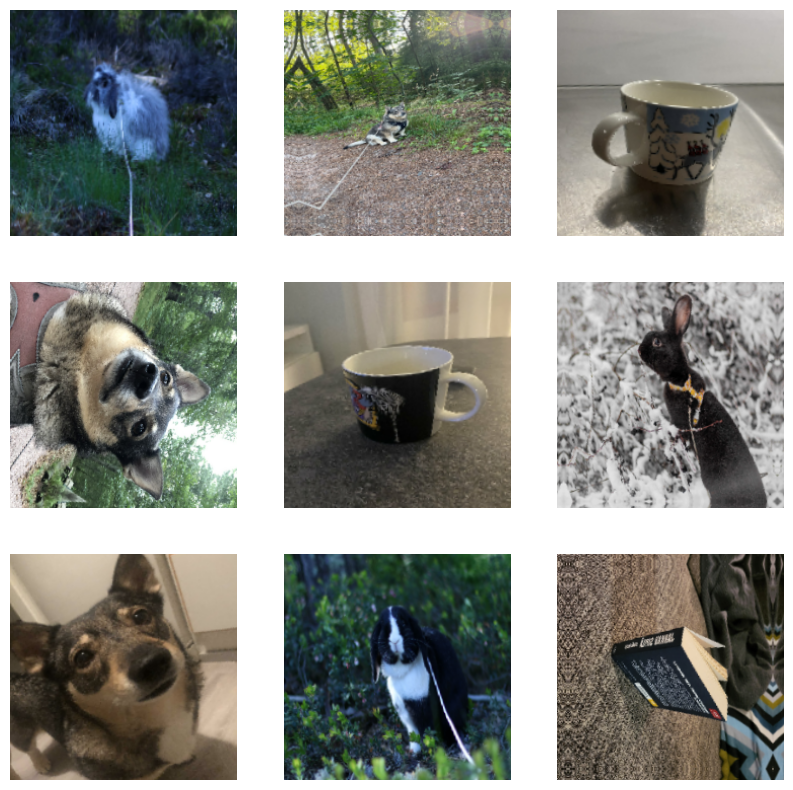

In [7]:
plt.figure(figsize=(10,10))
for images, _ in train_ds.take(1):
    for i in range(9):
        augmented_img = data_augmentation(images)[i].numpy().astype("uint8")
        plt.subplot(3,3,i+1)
        plt.imshow(augmented_img)
        plt.axis("off")
    break

### Normalization (for Model 1 only)

We use Rescaling(1./255) to convert pixel values from `0–255` to `0–1`.  

This normalization is used only in Model 1 (own CNN). Pretrained models use their own `preprocess_input()` function instead.


In [8]:
normalization_layer = layers.Rescaling(1./255)

### Dataset pipeline optimization

We apply:

- cache() loads images to memory for faster training  
- shuffle() avoids training on images in the same order  


In [9]:
train_ds = train_ds.cache().shuffle(1000)
val_ds = val_ds.cache()
test_ds = test_ds.cache()

#### Use of AI

AI was primarily used to verify the code and the solution logic, as well as to generate plots.